# Seawater RO design with exact gradients (`difflow_water`)

A seawater reverse-osmosis plant with a pressure exchanger, in `difflow_water`:

- seawater properties from Sharqawy, Lienhard & Zubair (2010);
- a plug-flow RO stage (solution-diffusion, film-theory polarization, feed-channel friction);
- a pressure exchanger and two pumps;
- the levelized cost of water (LCOW) with WaterTAP's default costing.

This notebook covers:

1. Seawater osmotic pressure.
2. One RO stage and its profile along the membrane.
3. The plant: recovery, specific energy, LCOW.
4. Exact gradients of the LCOW.
5. Scaling: mineral saturation indices at the membrane wall.
6. Minimizing the LCOW over RO pressure and membrane area, with a gypsum scaling limit.
7. A two-stage train.

The same plant agrees with WaterTAP 1.8.0 to within 0.3 % (`benchmarks/watertap/`).
Sources, verification status and what is ILLUSTRATIVE: `docs/unit-operations-water.md`.

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

import difflow_water as dw
from difflow_water import seawater as sw

## 1. Seawater osmotic pressure

`osmotic_pressure(T, S) = phi(T, S) m rho_w R T`, with the osmotic coefficient from Sharqawy et al. (2010), Eq. 49 (valid for 10-120 g/kg).

35 g/kg, 25 C: 25.9 bar


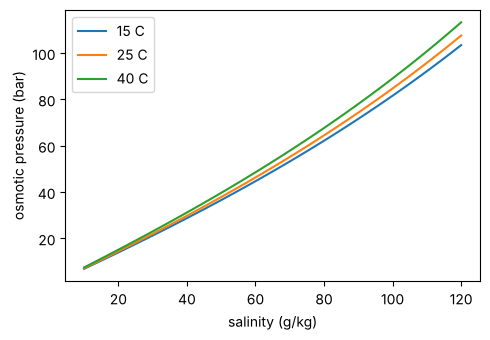

In [2]:
S = jnp.linspace(0.01, 0.12, 50)
fig, ax = plt.subplots(figsize=(5, 3.5))
for T in (288.15, 298.15, 313.15):
    ax.plot(S * 1e3, sw.osmotic_pressure(T, S) / 1e5, label=f"{T - 273.15:.0f} C")
ax.set_xlabel("salinity (g/kg)"); ax.set_ylabel("osmotic pressure (bar)"); ax.legend()
plt.tight_layout()
print(f"35 g/kg, 25 C: {float(sw.osmotic_pressure(298.15, 0.035)) / 1e5:.1f} bar")

## 2. One RO stage

1 L/s of 35 g/kg seawater at 65 bar through 50 m² of membrane. `A_w` and `B` are the water and salt permeability coefficients in WaterTAP's convention (the values WaterTAP's `RO_with_energy_recovery` example uses).

In [3]:
feed_hp = dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035, P=65e5)
ro = dw.ROStage(dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=50.0))
conc, perm, info = ro(feed_hp)
for k in ("recovery_mass_water", "salt_rejection", "salinity_permeate", "salinity_concentrate",
          "deltaP", "max_cp_modulus", "min_driving_pressure"):
    print(f"{k:22s} {float(info[k]):.4g}")

recovery_mass_water    0.4238
salt_rejection         0.9931
salinity_permeate      0.0002423
salinity_concentrate   0.05906
deltaP                 -2.127e+05
max_cp_modulus         1.297
min_driving_pressure   1.045e+06


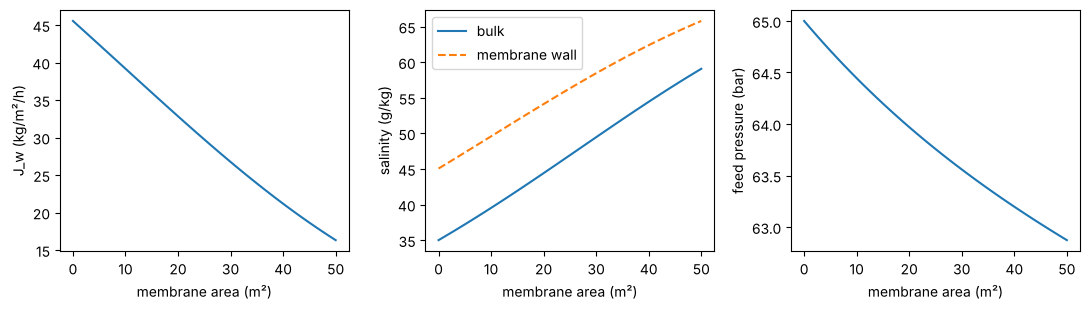

In [4]:
pr = info["profile"]
fig, axs = plt.subplots(1, 3, figsize=(11, 3.2))
axs[0].plot(pr["area"], pr["J_w"] * 3600, label="water flux")
axs[0].set_ylabel("J_w (kg/m²/h)")
axs[1].plot(pr["area"], pr["salinity"] * 1e3, label="bulk")
axs[1].plot(pr["area"], pr["salinity_wall"] * 1e3, "--", label="membrane wall")
axs[1].set_ylabel("salinity (g/kg)"); axs[1].legend()
axs[2].plot(pr["area"], pr["pressure"] / 1e5)
axs[2].set_ylabel("feed pressure (bar)")
for a in axs: a.set_xlabel("membrane area (m²)")
plt.tight_layout()

## 3. The plant

Intake seawater at 1 atm. The pressure exchanger pressurizes as much seawater as there is concentrate; the high-pressure pump takes the rest; a booster tops up the exchanger's outlet.

In [5]:
feed = dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035)
ro_params = dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=50.0)
r = dw.swro_performance(feed, ro_params, ro_pressure=65e5)
print(f"recovery          {float(r['recovery']):.3f}")
print(f"permeate salinity {float(r['salinity_permeate']) * 1e6:.0f} mg/kg")
print(f"brine salinity    {float(r['salinity_brine']) * 1e3:.1f} g/kg")
print(f"SEC               {float(r['SEC']):.3f} kWh/m³")
print(f"LCOW              {float(r['LCOW']):.4f} USD/m³")
print(f"HP pump {float(r['work_P1']) / 1e3:.2f} kW, booster {float(r['work_P2']) / 1e3:.2f} kW")

recovery          0.424
permeate salinity 242 mg/kg
brine salinity    59.1 g/kg
SEC               2.470 kWh/m³
LCOW              0.4104 USD/m³
HP pump 3.36 kW, booster 0.38 kW


## 4. Exact gradients

The LCOW as a function of RO pressure (bar), membrane area (m²) and water permeability. `jax.grad` differentiates through the RK4 integration along the membrane and the local flux solves (implicit-function gradients). A central difference is shown alongside as a check.

In [6]:
def lcow(P_bar, area, A_w=4.2e-12):
    p = dw.ROStageParams(A_w=A_w, B=3.5e-8, area=area)
    return dw.swro_performance(feed, p, P_bar * 1e5)["LCOW"]

g = jax.grad(lcow, argnums=(0, 1, 2))(65.0, 50.0, 4.2e-12)
fd_P = (lcow(65.01, 50.0) - lcow(64.99, 50.0)) / 0.02
print(f"dLCOW/dP    = {float(g[0]):+.4e} USD/m³ per bar   (central difference {float(fd_P):+.4e})")
print(f"dLCOW/darea = {float(g[1]):+.4e} USD/m³ per m²")
print(f"dLCOW/dA_w x A_w = {float(g[2]) * 4.2e-12:+.4e} USD/m³ (elasticity-like)")

dLCOW/dP    = +1.5338e-03 USD/m³ per bar   (central difference +1.5338e-03)
dLCOW/darea = -3.5946e-04 USD/m³ per m²
dLCOW/dA_w x A_w = -6.4397e-02 USD/m³ (elasticity-like)


## 5. Scaling: saturation indices at the membrane wall

`ROStageParams(scaling=True)` speciates the concentrate and the membrane-wall solution at the outlet with a Pitzer model (Harvie-Møller-Weare form as in PHRQPITZ; parameters from PHREEQC's `pitzer.dat`; agrees with PHREEQC to 0.0004 in SI) and reports saturation indices `SI = log10(IAP/K)`. The feed is Reference-Composition seawater at pH 8.1 (MacInnes scale, PHREEQC's; ILLUSTRATIVE, use the measured pH). All solutes are taken as rejected alike and CO2 stays in.

Seawater is already supersaturated in calcite (SI ≈ 0.7). In single-pass seawater RO the osmotic pressure caps recovery before gypsum saturates, as the sweep shows; calcite (handled with antiscalant or acid) is the one to watch.

max recovery in the sweep 0.644; gypsum SI at the wall stays <= -0.11


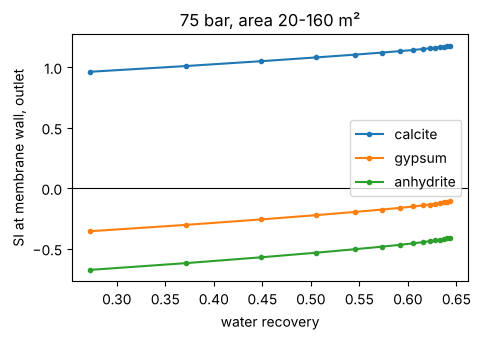

In [7]:
areas = np.linspace(20, 160, 15)
rows = []
for A in areas:
    o = dw.swro_performance(feed, dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=A, scaling=True), 75e5)
    w = o["ro"]["SI_wall_outlet"]
    rows.append((float(o["recovery"]), float(w["Calcite"]), float(w["Gypsum"]), float(w["Anhydrite"])))
rows = np.array(rows)
fig, ax = plt.subplots(figsize=(5, 3.5))
for i, name in enumerate(["calcite", "gypsum", "anhydrite"], start=1):
    ax.plot(rows[:, 0], rows[:, i], "o-", ms=3, label=name)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("water recovery"); ax.set_ylabel("SI at membrane wall, outlet"); ax.legend()
ax.set_title("75 bar, area 20-160 m²")
plt.tight_layout()
print(f"max recovery in the sweep {rows[:, 0].max():.3f}; gypsum SI at the wall stays <= {rows[:, 2].max():+.2f}")

## 6. Minimum LCOW with a scaling limit

Minimize the LCOW over RO pressure and area subject to

- calcite SI ≤ 0.9 at the membrane wall. The value is ILLUSTRATIVE: a stand-in for an antiscalant's tolerance, chosen low enough to bind so the constraint is seen at work,
- permeate salinity ≤ 500 mg/kg,
- 40 ≤ P ≤ 82 bar, 20 ≤ area ≤ 150 m².

The objective and constraints are one jitted function (speciation included); SLSQP gets their exact gradients from `jax.jacobian`.

In [8]:
@jax.jit
def plant(x):
    P_bar, area = x[0], x[1]
    ro_p = dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=area, scaling=True)
    out = dw.swro_performance(feed, ro_p, P_bar * 1e5)
    return jnp.stack([out["LCOW"], out["ro"]["SI_wall_outlet"]["Calcite"], out["salinity_permeate"]])

jac = jax.jit(jax.jacobian(plant))
cons = [
    {"type": "ineq", "fun": lambda x: 0.9 - float(plant(x)[1]), "jac": lambda x: -np.asarray(jac(x)[1])},
    {"type": "ineq", "fun": lambda x: 5e-4 - float(plant(x)[2]), "jac": lambda x: -np.asarray(jac(x)[2])},
]
x0 = np.array([65.0, 50.0])
res = minimize(lambda x: float(plant(x)[0]), x0, jac=lambda x: np.asarray(jac(x)[0]),
               bounds=[(40.0, 82.0), (20.0, 150.0)], constraints=cons, method="SLSQP")
print(res.message)
P_opt, A_opt = res.x
best = dw.swro_performance(feed, dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=A_opt, scaling=True), P_opt * 1e5)
print(f"P = {P_opt:.1f} bar, area = {A_opt:.1f} m²")
s0 = plant(x0)
print(f"start: LCOW {float(s0[0]):.4f} USD/m³ with calcite SI {float(s0[1]):.2f} (violates the 0.9 limit)")
print(f"LCOW {float(best['LCOW']):.4f} USD/m³, "
      f"SEC {float(best['SEC']):.3f} kWh/m³, recovery {float(best['recovery']):.3f}, "
      f"gypsum SI (wall) {float(best['ro']['SI_wall_outlet']['Gypsum']):+.2f}, "
      f"calcite SI (wall) {float(best['ro']['SI_wall_outlet']['Calcite']):+.2f}")

Optimization terminated successfully


P = 53.2 bar, area = 46.5 m²
start: LCOW 0.4104 USD/m³ with calcite SI 1.00 (violates the 0.9 limit)
LCOW 0.4129 USD/m³, SEC 2.207 kWh/m³, recovery 0.296, gypsum SI (wall) -0.42, calcite SI (wall) +0.90


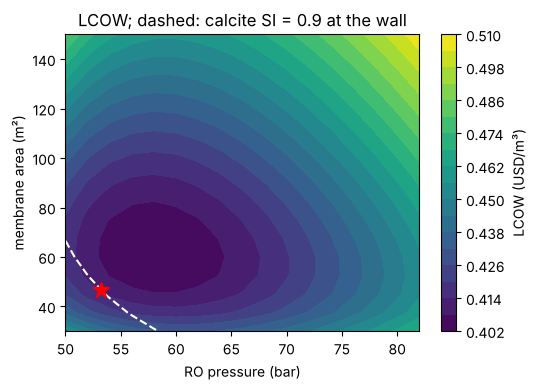

In [9]:
Ps = np.linspace(50, 82, 17); As = np.linspace(30, 150, 17)
grid = np.array([[np.asarray(plant(jnp.array([p, a]))) for p in Ps] for a in As])
fig, ax = plt.subplots(figsize=(5.5, 4))
cs = ax.contourf(Ps, As, grid[..., 0], levels=20, cmap="viridis"); fig.colorbar(cs, label="LCOW (USD/m³)")
ax.contour(Ps, As, grid[..., 1], levels=[0.9], colors="w", linestyles="--")
ax.plot(P_opt, A_opt, "r*", ms=12)
ax.set_xlabel("RO pressure (bar)"); ax.set_ylabel("membrane area (m²)")
ax.set_title("LCOW; dashed: calcite SI = 0.9 at the wall")
plt.tight_layout()

## 7. A two-stage train

`ROTrain` runs stages in series on the concentrate side, with optional interstage booster pumps; the permeates are mixed.

In [10]:
feed_hp = dw.make_seawater_stream(flow_vol=1e-3, salinity=0.035, P=65e5)
s1 = dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=35.0)
s2 = dw.ROStageParams(A_w=4.2e-12, B=3.5e-8, area=35.0, scaling=True)
conc, perm, tinfo = dw.ROTrain(dw.ROTrainParams(stages=[s1, s2], boost=[10e5]))(feed_hp)
print(f"train recovery {float(tinfo['recovery_mass_water']):.3f}, permeate {float(tinfo['salinity_permeate']) * 1e6:.0f} mg/kg, "
      f"booster {float(tinfo['work_boosters']) / 1e3:.2f} kW")
print("stage 2 wall SI:", {k: round(float(v), 2) for k, v in tinfo["stages"][1]["SI_wall_outlet"].items()
                           if k in ("Calcite", "Gypsum", "Anhydrite")})

train recovery 0.548, permeate 297 mg/kg, booster 0.83 kW
stage 2 wall SI: {'Anhydrite': -0.51, 'Calcite': 1.21, 'Gypsum': -0.2}


## Notes

- The costs are WaterTAP's default parameters (USD 2018): a benchmark convention for comparing with WaterTAP, not a cost estimate for a real plant.
- The feed-channel correlations (mass-transfer coefficient, friction factor) are WaterTAP's and are unverified against their papers; see the references table in `docs/unit-operations-water.md`.
- The saturation indices are at 1 atm (no pressure correction of K), assume equal rejection of every solute, and ignore kinetics: a supersaturated calcite brine with antiscalant may not scale. They say where scaling becomes possible, not that it happens.
- The Pitzer parameters are PHREEQC's `pitzer.dat` (second-hand to Harvie, Møller & Weare 1984 and later work); the equations are content-verified against PHRQPITZ (Plummer et al. 1988).